In [1]:
%run "/Users/Farid Srouji/Documents/Research/master/NYTimes/code/PredictionIpynb/DataPrep/Basic_train_test_split_classification.ipynb"

setting to false
x train:  (400, 2)
x test:  (105, 2)
y train:  (400, 1)
y test:  (105, 1)


In [2]:
ModelName = "RandomForestClassifier"

In [3]:
X_test

,NewsVolume return,vix_ln_return(t-1)
Date,,
2021-12-30,-0.101096,-0.034216
2021-12-31,-0.266629,0.022171
2022-01-03,0.367725,-0.006368
2022-01-04,0.297252,-0.036669
2022-01-05,0.014185,0.018502
...,...,...
2022-05-24,-0.074108,-0.032813
2022-05-25,0.268264,0.033492
2022-05-26,-0.268264,-0.037362


In [4]:
from sklearn import preprocessing
from sklearn import utils

# lab_enc = preprocessing.LabelEncoder()
# y_train_encoded = lab_enc.fit_transform(y_train)

In [5]:
from treeinterpreter import treeinterpreter as ti
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier()
rf.fit(X_train, y_train)
prediction = rf.predict(X_test)
# prediction, bias, contributions = ti.predict(rf, X_test)

In [6]:
len(prediction)

105

In [7]:
len(X_test)

105

In [8]:
# prediction = lab_enc.inverse_transform(prediction)

In [9]:
# from sklearn.metrics import r2_score
# r2_score(prediction, y_test)

In [10]:
# idx = y_test.index
# predictions_df = pd.DataFrame(data=prediction[0:], index = idx, columns=['predicted_value'] )
# predictions_df["actual_value"]= y_test["vix_ln_return"]

In [11]:
import numpy as np 
import pandas as pd 
predictions_df = pd.DataFrame(data=prediction, index = y_test.index, columns=['VIX'])
predictions_df['actual_value'] = y_test#['VIX return'].values
predictions_df['predicted_value'] = predictions_df['VIX']# return']
predictions_df.drop(columns="VIX",inplace=True)
predictions_df['predicted_value'] = predictions_df['predicted_value'].apply(np.float64)

            actual_value  predicted_value
Date                                     
2021-12-30             1             -1.0
2021-12-31            -1             -1.0
2022-01-03            -1              1.0
2022-01-04             1             -1.0
2022-01-05             1              1.0
...                  ...              ...
2022-05-24             1             -1.0
2022-05-25            -1              1.0
2022-05-26            -1              1.0
2022-05-27            -1              1.0
2022-05-31             1              1.0

[105 rows x 2 columns]
RandomForestClassifier


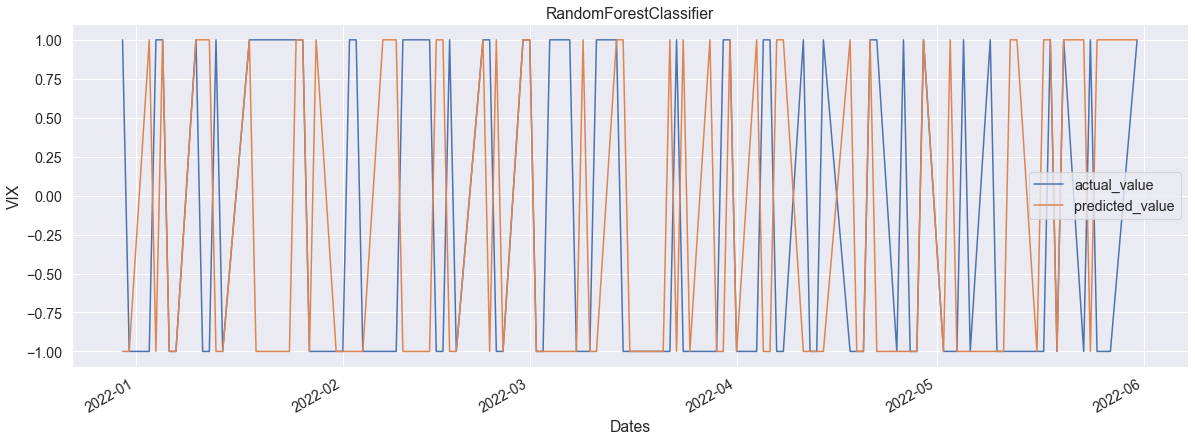

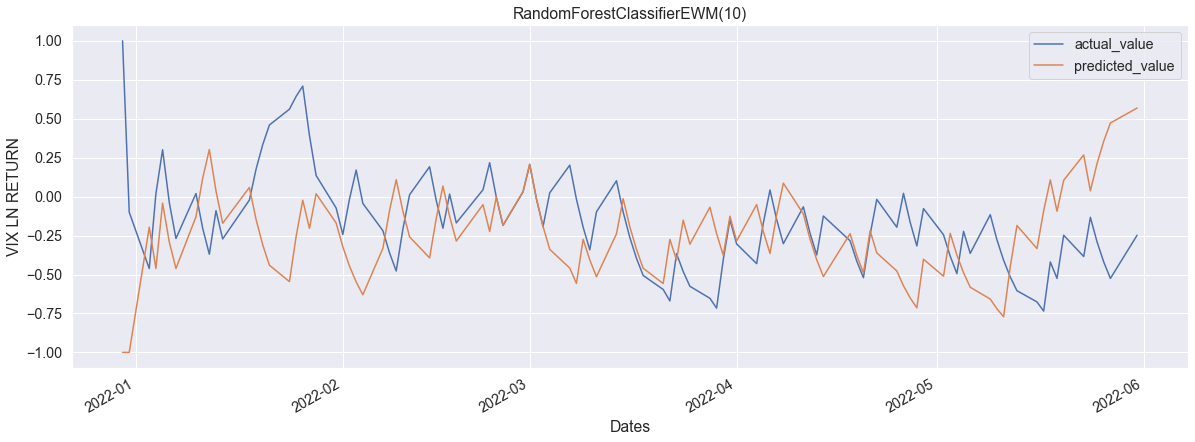

In [12]:
%run "/Users/Farid Srouji/Documents/Research/master/NYTimes/code/PredictionIpynb/ModelSaveImages.ipynb"

In [13]:
predictions_rfc = predictions_df.predicted_value
predictions_rfc.to_pickle("/Users/Farid Srouji/Documents/Research/master/NYTimes/data/pkl/Predictions/predictions_rfc.pkl")

In [14]:
target_VIX = y_test.squeeze()
directions_rf = directions_rf - directions_rf.shift()
directions_VIX = target_VIX - target_VIX.shift()

count_pos(directions_rf * directions_VIX)

NameError: name 'directions_rf' is not defined

In [ ]:
# predictions_plot = predictions_df["predicted_value"].plot()
# # fig = y_test.plot(ax = predictions_plot,figsize=(20,10)).get_figure()
# fig = df_part3['vix_ln_return'].plot(ax = predictions_plot,figsize=(20,10)).get_figure()

# fig.savefig("/Users/Farid Srouji/Documents/Research/master/NYTimes/images/PredictionModels/random_forest_without_smoothing_sp500.png")
# matplotlib.pyplot.savefig("C:\Users\Farid\Documents\Project Options predictions\graphs\random forest without smoothing.png")

# RandomForestClassifier

In [ ]:
# Fitting Random Forest Classification
# to the Training set
from sklearn.ensemble import RandomForestClassifier
 
# n_estimators can be said as number of
# trees, experiment with n_estimators
# to get better results
model = RandomForestClassifier(n_estimators = 501,
                            criterion = 'entropy')
y_train = np.nan_to_num(y_train)
numpy_df_train = np.nan_to_num(numpy_df_train)
model.fit(numpy_df_train, y_train)
                            
# model.fit(X_train, y_train)

In [ ]:
# Predicting the Test set results
y_pred = model.predict(X_test)
 
y_pred

In [ ]:
# Making the Confusion Matrix
from sklearn.metrics import confusion_matrix
 
cm = confusion_matrix(y_test, y_pred)
 
cm